# AutoSplice · CocoGlide 평가 함수 사용 예제

- 작성자: kimjaehak
- 상태: **완료 — 사용자 Colab 실행·저장 출력 확인 (2026-11-17)**
- 작성일: 2026-11-17
- 목적: 공통 분할 목록을 읽고 실제 이미지·마스크에 평가 함수를 적용하는 방법 확인
- 기준 실험: 해당 없음
- [개별 보고서](../../docs/eda/EXP_kimjaehak_001_evaluation_example.md)

모델을 학습하거나 추론하지 않는다. 정답 마스크를 일부 바꾼 **설명용 예측**을 사용한다. 아래 숫자는 모델 성능이 아니며, CocoGlide를 이용해 학습 설정이나 임계값을 선택하지 않는다.

AutoSplice는 저장된 원본 ID 분할을 사용한다. 이 예제에서 원본 ID를 다시 나누지 않는다. CocoGlide는 전체를 외부 테스트용으로 유지하며, 여기서는 사용법을 보여줄 한 쌍만 읽는다.
2026-11-17: 팀원 안내를 위해 4~7절 설명을 보강함. 코드·설정·저장 출력은 변경하지 않았으며 재실행하지 않음.


## 1. Colab 준비

공유 Drive의 `AI_Forensics` 아래에 다음 구조를 준비한다. `project/`는 제공한 실행용 ZIP의 `project` 폴더를 올리면 된다. 데이터 ZIP은 기존 파일을 그대로 사용한다.

```text
AI_Forensics/
├── datasets/
│   ├── AutoSplice/AutoSplice.zip
│   └── CocoGlide.zip
└── project/
    ├── scripts/
    │   ├── evaluation.py
    │   ├── preprocessing.py
    │   ├── datasets.py
    │   └── splits/autosplice_seed42.csv
    ├── notebooks/eda/EXP_kimjaehak_001_evaluation_example.ipynb
    └── docs/eda/EXP_kimjaehak_001_evaluation_example.md
```

로컬 프로젝트의 이 노트북을 VS Code에서 열고 Google Colab 확장의 원격 커널을 선택한다. 팀원이 위에서부터 실행한 뒤 출력을 포함해 `.ipynb`를 저장하고, 다시 열어 저장 여부를 확인한다. 보고서는 저장된 출력을 기준으로 갱신한다.

실행은 Colab 런타임에서만 진행한다. 데이터 ZIP과 공통 코드는 위 공유 Drive 경로에서 읽는다. GPU는 사용하지 않는다. NumPy, Pillow, pandas, matplotlib이 필요하며, 실제 실행 버전을 출력으로 기록한다. 모델 비교용 팀 공통 버전은 아직 미정이다.


In [3]:
from pathlib import Path
from google.colab import drive

drive.mount("/content/drive")
shared_root = Path("/content/drive/MyDrive/AI_Forensics")
project_root = shared_root / "project"
archive_paths = {
    "AutoSplice": shared_root / "datasets/AutoSplice/AutoSplice.zip",
    "CocoGlide": shared_root / "datasets/CocoGlide.zip",
}
work_root = Path("/content")
data_root = work_root / "datasets"
extract_paths = {"AutoSplice": data_root, "CocoGlide": data_root / "CocoGlide"}
split_path = project_root / "scripts/splits/autosplice_seed42.csv"

if not (project_root / "scripts/evaluation.py").is_file():
    raise FileNotFoundError("공유 Drive의 AI_Forensics/project에 공통 코드를 준비해야 함.")

print("실행 환경: Colab 런타임")
print("프로젝트:", project_root)
print("데이터 해제 위치:", data_root)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
실행 환경: Colab 런타임
프로젝트: /content/drive/MyDrive/AI_Forensics/project
데이터 해제 위치: /content/datasets


In [4]:
import importlib.metadata
import platform
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

sys.path.insert(0, str(project_root))
from scripts.preprocessing import load_rgb, load_binary_mask
from scripts.datasets import sha256, prepare_dataset_zip, autosplice_records, cocoglide_records
from scripts.evaluation import confusion_counts, pixel_f1, iou, false_positive_rate

print("Python:", platform.python_version())
print("OS:", platform.platform())
for package in ("numpy", "Pillow", "pandas", "matplotlib"):
    print(package, importlib.metadata.version(package))
print("GPU: 사용하지 않음")
print("코드 기준: 커밋 전 파일, 아래 SHA-256으로 기록함.")
for relative in ("scripts/evaluation.py", "scripts/preprocessing.py", "scripts/datasets.py", "scripts/splits/autosplice_seed42.csv"):
    print(relative, sha256(project_root / relative))

threshold = 0.5
mask_foreground = 255
print("예제 설정:", dict(threshold=threshold, mask_foreground=mask_foreground, autosplice_quality=100))

Python: 3.13.16
OS: Linux-6.6.159+-x86_64-with-glibc2.39
numpy 2.4.6
Pillow 11.3.0
pandas 2.2.3
matplotlib 3.10.0
GPU: 사용하지 않음
코드 기준: 커밋 전 파일, 아래 SHA-256으로 기록함.
scripts/evaluation.py ad400aa2cf453bd54ecc3e73abc38bc80cb1f7239eea7489b3072dae96dfcb52
scripts/preprocessing.py 69809276be12200a3cd2ef1e96364a7d168b39cae0a2cce1946f84d7ce74db07
scripts/datasets.py 435215ef08c2c43ce2f84795d783895074eee85f8e062f28ea8ee6acabad3e88
scripts/splits/autosplice_seed42.csv f8a2893ab93b82264e6434fa0c26f09472de05bd98829065c2a0db846ace7b1e
예제 설정: {'threshold': 0.5, 'mask_foreground': 255, 'autosplice_quality': 100}


## 2. ZIP 복사와 압축 해제

`scripts/datasets.py`의 `prepare_dataset_zip`을 호출해 ZIP 복사·해시 확인·압축 해제를 함께 처리한다. Drive 마운트와 경로 설정은 위 셀에 둔다. AutoSplice ZIP에는 `AutoSplice/`가 포함돼 있고 CocoGlide ZIP에는 포함돼 있지 않으므로 해제 위치를 다르게 지정한다.

첨부받은 ZIP의 SHA-256을 확인한다. ZIP이 다르면 같은 데이터라고 간주하지 않고 중단한다. 완료 표시는 모든 파일의 압축 해제가 끝난 뒤에만 남긴다. 같은 런타임에서 재실행하면 완료된 해제를 재사용한다. 해제 파일을 수정하거나 삭제했다면 해당 해제 위치의 `.AutoSplice.complete` 또는 `.CocoGlide.complete`를 지우고 다시 실행한다.

In [5]:
archive_hashes = {
    "AutoSplice": "0d94e2df6842f44c11e21ee207707c49fd9717ec89048bd6f28fc1e07c4a5e36",
    "CocoGlide": "fc848643ad0a81010ba2a6ab8c055762782f54e4fb9e407210dbfe1c3b538af9",
}

for name, source in archive_paths.items():
    prepare_dataset_zip(source, work_root / f"{name}.zip", extract_paths[name], archive_hashes[name])


AutoSplice ZIP SHA-256 확인 및 압축 해제 완료
CocoGlide ZIP SHA-256 확인 및 압축 해제 완료


## 3. 고정 분할과 파일 연결

AutoSplice의 원본 ID 2,273개를 숫자 순으로 정렬하고 `random.Random(42).shuffle`로 한 번 섞었다. 학습은 `2273 × 80 // 100 = 1818`, 검증은 `2273 × 10 // 100 = 227`, 나머지 228개는 테스트로 배정했다. CSV에는 ID 순으로 저장했다.

원본에 연결된 조작본과 JPEG 품질별 변형은 모두 같은 split을 사용한다. 조작본이 없는 정상 원본도 분할 대상에 포함했다. 최종 파일 수 비율은 ID 비율과 다를 수 있다. 분할 생성 방법과 데이터 해시는 [분할 기록](../../scripts/splits/README.md)에 있다.

In [6]:
expected_split_hash = "f8a2893ab93b82264e6434fa0c26f09472de05bd98829065c2a0db846ace7b1e"
if sha256(split_path) != expected_split_hash:
    raise ValueError("공유한 분할 CSV와 일치해야 함.")

split_table = pd.read_csv(split_path, dtype=str)
display(split_table.head())
display(split_table.groupby("split").size().reindex(["train", "val", "test"]).rename("original_ids").to_frame())

auto_by_quality = {quality: autosplice_records(data_root / "AutoSplice", split_path, quality) for quality in (100, 90, 75)}
auto_records = auto_by_quality[100]
coco_records = cocoglide_records(data_root / "CocoGlide")

for quality, records in auto_by_quality.items():
    frame = pd.DataFrame(records)
    assert frame.groupby("original_id")["split"].nunique().max() == 1
    signature = {(row["kind"], row["image_path"].name, row["split"]) for row in records}
    baseline = {(row["kind"], row["image_path"].name, row["split"]) for row in auto_records}
    assert signature == baseline
    print(f"JPEG {quality}: 원본·조작본 분할 일치 확인")

auto_table = pd.DataFrame(auto_records)
coco_table = pd.DataFrame(coco_records)
print("AutoSplice: 조작본은 JPEG 100 기준, 정상 이미지는 제공 파일 그대로 사용")
display(auto_table.groupby(["split", "kind"]).size().unstack().reindex(["train", "val", "test"]))
print("CocoGlide: 원본 PNG, 외부 테스트 전용")
display(coco_table.groupby(["split", "kind"]).size().unstack())

,original_id,split
0,39406,train
1,39436,train
2,39446,test
3,39450,train
4,39457,train


,original_ids
split,
train,1818
val,227
test,228


JPEG 100: 원본·조작본 분할 일치 확인
JPEG 90: 원본·조작본 분할 일치 확인
JPEG 75: 원본·조작본 분할 일치 확인
AutoSplice: 조작본은 JPEG 100 기준, 정상 이미지는 제공 파일 그대로 사용


kind,manipulated,normal
split,,
train,2925,1818
val,361,227
test,335,228


CocoGlide: 원본 PNG, 외부 테스트 전용


kind,manipulated,normal
split,,
external_test,512,512


## 4. 두 데이터셋의 이미지와 마스크 읽기

**목적: 실제 이미지와 정답 마스크가 올바르게 연결되고 읽히는지 확인함. 이 단계에서는 예측이나 지표를 계산하지 않음.**

AutoSplice는 train의 첫 조작 파일을 이름순으로 선택하고, CocoGlide는 `table.csv`의 첫 조작 행을 선택함. 점수나 시각적 난이도를 보고 고르지 않음. 두 데이터셋에서 정상·조작 이미지와 정답 마스크를 한 묶음씩 읽음.

- `datasets.py`: 조작 이미지에 대응하는 원본·마스크 경로를 연결함.
- `load_rgb()`: 정상·조작 이미지를 RGB 배열로 읽음.
- `load_binary_mask()`: 마스크의 255를 조작 영역 1로 바꾸고 정상 영역 0은 유지함.
- 출력: 선택한 ID·파일명·크기·마스크 값과 정상 이미지 → 조작 이미지 → 정답 마스크 순서의 그림을 보여줌.

그림에서 바뀐 영역과 마스크의 흰 부분이 대응하는지, 이미지와 마스크 크기가 맞는지 확인하면 됨. 두 표본의 데이터 로드 확인이며 전체 데이터 검증은 아님. 원본 크기를 유지하고 ELA·JPEG 변환·크롭·리사이즈는 적용하지 않음. 정상 이미지용 0 마스크는 6번에서 만듦.


AutoSplice split: train ID: 39406
조작: 39406_0.jpg 정상: 39406.jpg 마스크: 39406_mask.png
조작 크기: (256, 374, 3) 정상 크기: (256, 374, 3) 마스크 값: [0, 1]
CocoGlide split: external_test ID: 114871
조작: glide_inpainting_val2017_114871_up.png 정상: dining table_114871.png 마스크: dining table_114871_mask.png
조작 크기: (256, 256, 3) 정상 크기: (256, 256, 3) 마스크 값: [0, 1]


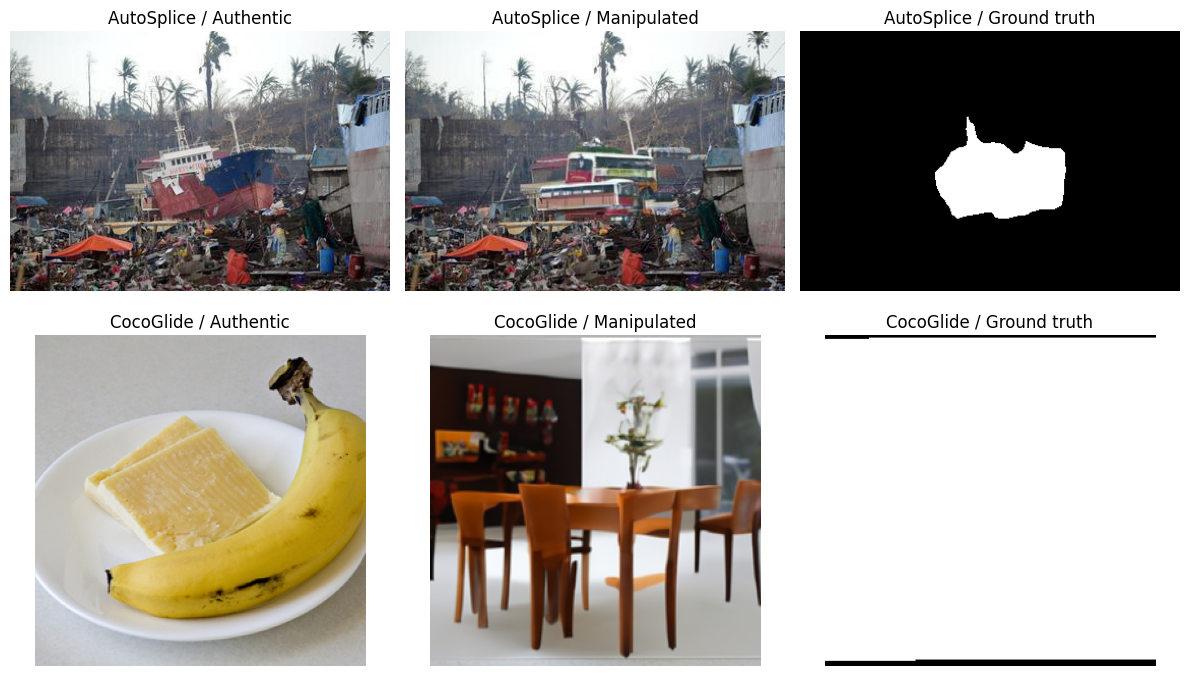

In [7]:
selected_auto = next(row for row in auto_records if row["split"] == "train" and row["kind"] == "manipulated")
selected_coco = next(row for row in coco_records if row["kind"] == "manipulated")
samples = {}

for row in (selected_auto, selected_coco):
    forged = load_rgb(row["image_path"])
    real = load_rgb(row["real_path"])
    mask = load_binary_mask(row["mask_path"], foreground_value=mask_foreground)
    if forged.shape[:2] != mask.shape:
        raise ValueError("조작 이미지와 마스크 크기가 일치해야 함.")
    samples[row["dataset"]] = dict(row=row, forged=forged, real=real, mask=mask)
    print(row["dataset"], "split:", row["split"], "ID:", row["original_id"])
    print("조작:", row["image_path"].name, "정상:", row["real_path"].name, "마스크:", row["mask_path"].name)
    print("조작 크기:", forged.shape, "정상 크기:", real.shape, "마스크 값:", np.unique(mask).tolist())

fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for axes_row, (name, sample) in zip(axes, samples.items()):
    for ax, key, title in zip(axes_row, ("real", "forged", "mask"), ("Authentic", "Manipulated", "Ground truth")):
        ax.imshow(sample[key], cmap="gray", vmin=0, vmax=1) if key == "mask" else ax.imshow(sample[key])
        ax.set_title(f"{name} / {title}")
        ax.axis("off")
plt.tight_layout()
plt.show()

## 5. 설명용 예측 만들기

**목적: 조작 이미지의 예측을 얻었다고 가정하고, 정답과 비교해 Pixel F1·IoU를 계산하는 방법을 확인함.**

이 예제에서는 모델을 사용하지 않음. 정답 마스크를 일부러 바꿔 예측을 흉내 냄. 따라서 아래 점수는 모델 성능이 아님.

픽셀 하나를 비교할 때 네 가지 경우가 있음. 여기서 양성은 조작을 뜻함.

| 구분 | 실제 정답 | 예측 | 의미 |
| --- | --- | --- | --- |
| TP | 조작(1) | 조작(1) | 조작을 조작으로 맞힘 |
| FP | 정상(0) | 조작(1) | 정상을 조작으로 잘못 판단함(오탐) |
| FN | 조작(1) | 정상(0) | 조작을 정상으로 놓침(누락) |
| TN | 정상(0) | 정상(0) | 정상을 정상으로 맞힘 |

아래 코드는 다음 순서로 진행함.

1. `demo = mask.copy()`로 정답과 같은 예측을 만듦.
2. 조작 픽셀을 행 순서로 나열해 매 5번째를 0으로 바꿈. 조작 픽셀의 약 20%를 놓치는 FN을 만듦.
3. 정상 픽셀의 매 100번째를 1로 바꿈. 정상 픽셀의 약 1%를 오탐하는 FP를 만듦. 두 비율의 기준은 각각 조작 픽셀 수와 정상 픽셀 수임.
4. 예측 1에는 0.9, 예측 0에는 0.1을 배정해 설명용 확률을 만듦. `probabilities >= 0.5`로 이진화하면 여기서는 원래 demo와 같은 예측이 됨. 실제 모델의 확률을 이진 마스크로 바꾸는 위치를 보여주기 위한 과정임.
5. `confusion_counts(mask, prediction)`으로 TP·FP·FN·TN을 구하고, `pixel_f1(tp, fp, fn)`과 `iou(tp, fp, fn)`을 호출함.

Pixel F1은 `2*TP / (2*TP + FP + FN)`, IoU는 `TP / (TP + FP + FN)`임. 아래 출력에서 오류가 있는 예측의 점수와 정답·예측 그림을 함께 확인하면 됨. 픽셀을 바꾸는 규칙이 정해져 있으므로 같은 마스크에서는 같은 결과가 나옴.

실제 모델을 연결할 때는 정답으로 demo를 만드는 부분을 제거하고, `probabilities`에 모델이 출력한 `(H, W)` 조작 확률을 넣음. 정답은 평가할 때 비교 대상으로만 사용함.


AutoSplice 설명용 예측
{'tp': 6496, 'fp': 877, 'fn': 1625, 'tn': 86746, 'pixel_f1': 0.8385181360526656, 'iou': 0.7219382084907757}
CocoGlide 설명용 예측
{'tp': 51024, 'fp': 18, 'fn': 12756, 'tn': 1738, 'pixel_f1': 0.8887495427705492, 'iou': 0.7997742875952224}


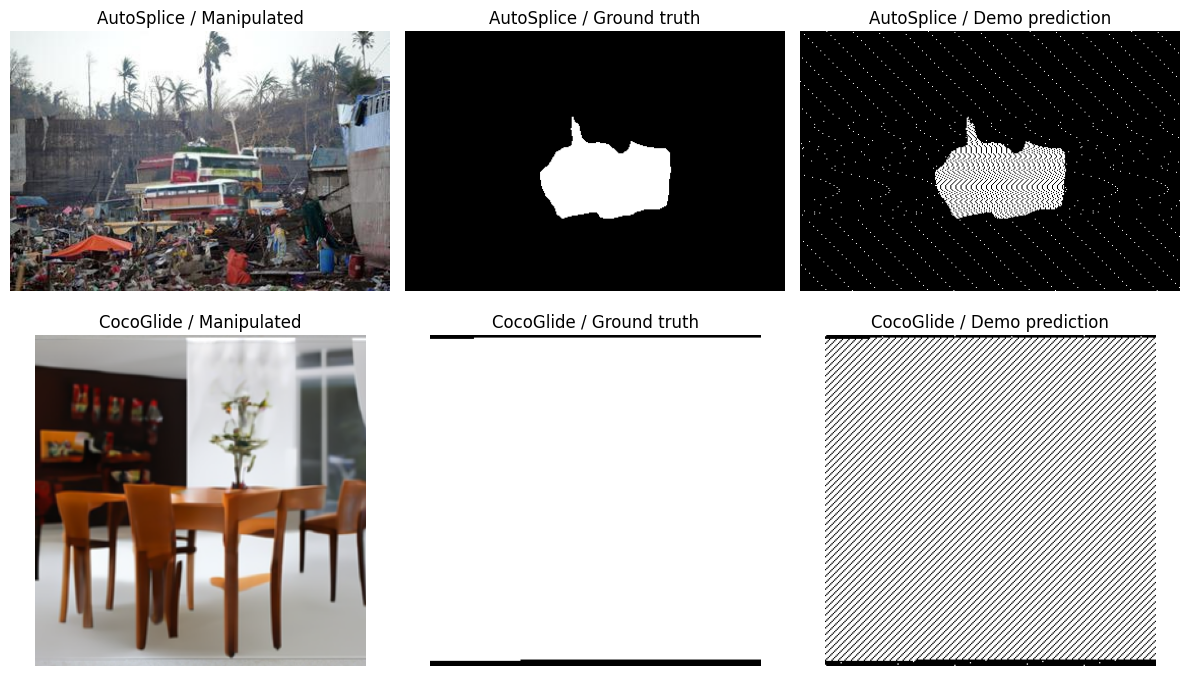

In [8]:
for name, sample in samples.items():
    mask = sample["mask"]
    demo = mask.copy()
    positive_pixels = np.flatnonzero(mask.ravel() == 1)
    negative_pixels = np.flatnonzero(mask.ravel() == 0)
    demo.ravel()[positive_pixels[::5]] = 0
    demo.ravel()[negative_pixels[::100]] = 1
    probabilities = np.where(demo == 1, 0.9, 0.1)
    prediction = probabilities >= threshold
    sample["prediction"] = prediction

    tp, fp, fn, tn = confusion_counts(mask, prediction)
    f1 = pixel_f1(tp, fp, fn)
    iou_score = iou(tp, fp, fn)
    print(name, "설명용 예측")
    print(dict(tp=tp, fp=fp, fn=fn, tn=tn, pixel_f1=f1, iou=iou_score))

fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for axes_row, (name, sample) in zip(axes, samples.items()):
    axes_row[0].imshow(sample["forged"])
    axes_row[1].imshow(sample["mask"], cmap="gray", vmin=0, vmax=1)
    axes_row[2].imshow(sample["prediction"], cmap="gray", vmin=0, vmax=1)
    for ax, title in zip(axes_row, ("Manipulated", "Ground truth", "Demo prediction")):
        ax.set_title(f"{name} / {title}")
        ax.axis("off")
plt.tight_layout()
plt.show()

## 6. 정상 이미지와 오탐률

**목적: 조작이 없는 정상 이미지에서 잘못 표시한 픽셀의 비율을 계산하는 방법을 확인함.**

정상 이미지의 정답은 전부 0임. `np.zeros()`로 정상 이미지와 같은 높이·너비의 정답 마스크를 만듦. 예측에는 좌측 상단의 작은 사각형만 1로 표시해 일부러 오탐을 만듦.

사각형 높이·너비가 각각 원본의 약 10%이므로 면적은 전체의 약 1%임. 정수 나눗셈 때문에 정확히 1%는 아닐 수 있음.

`confusion_counts()`로 픽셀 수를 구한 뒤 `false_positive_rate(fp, tn)`을 호출함. 계산식은 `FP / (FP + TN)`이며, 정상 이미지의 전체 픽셀 중 조작으로 잘못 판단한 비율임. 이미지 몇 장을 오탐했는지 세는 이미지 단위 오탐률과는 다름.

출력 그림에서 정답은 모두 검정이고 예측의 좌측 상단만 흰색인지 확인하면 됨. 출력값 0.01은 약 1%를 뜻함. 이 예제에서는 정상 이미지의 F1·IoU를 기록하지 않고 픽셀 오탐률을 사용함. 정상·조작 구분은 공통 지표 함수가 자동 처리하지 않으므로 노트북에서 수행함.


AutoSplice {'tp': 0, 'fp': 925, 'fn': 0, 'tn': 94819, 'normal_pixel_fpr': 0.009661179812834224}
CocoGlide {'tp': 0, 'fp': 625, 'fn': 0, 'tn': 64911, 'normal_pixel_fpr': 0.0095367431640625}


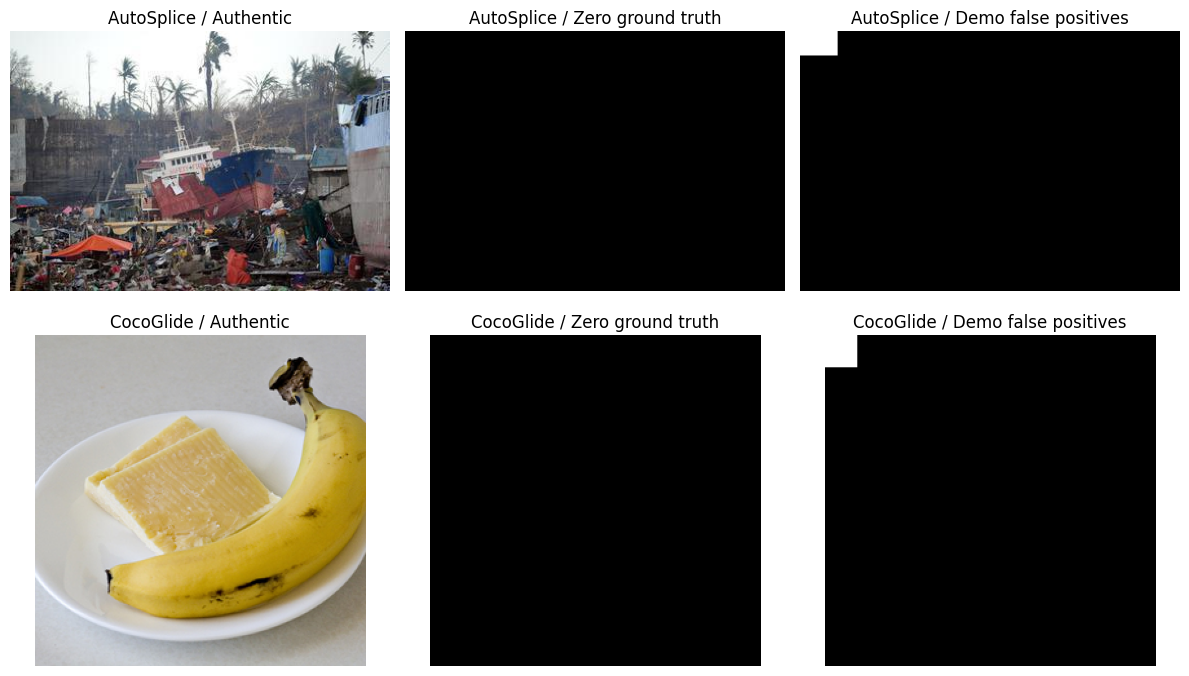

In [9]:
for name, sample in samples.items():
    normal_mask = np.zeros(sample["real"].shape[:2], dtype=np.uint8)
    normal_prediction = normal_mask.copy()
    height, width = normal_mask.shape
    normal_prediction[:max(1, height // 10), :max(1, width // 10)] = 1
    sample["normal_mask"] = normal_mask
    sample["normal_prediction"] = normal_prediction

    tp, fp, fn, tn = confusion_counts(normal_mask, normal_prediction)
    fpr = false_positive_rate(fp, tn)
    print(name, dict(tp=tp, fp=fp, fn=fn, tn=tn, normal_pixel_fpr=fpr))

fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for axes_row, (name, sample) in zip(axes, samples.items()):
    axes_row[0].imshow(sample["real"])
    axes_row[1].imshow(sample["normal_mask"], cmap="gray", vmin=0, vmax=1)
    axes_row[2].imshow(sample["normal_prediction"], cmap="gray", vmin=0, vmax=1)
    for ax, title in zip(axes_row, ("Authentic", "Zero ground truth", "Demo false positives")):
        ax.set_title(f"{name} / {title}")
        ax.axis("off")
plt.tight_layout()
plt.show()

## 7. 여러 예측 상황과 분모 0 확인

**목적: 다섯 가지 예측 상황을 비교하고 평가 함수가 예상한 값을 반환하는지 확인함.**

5·6번에서 만든 예측을 재사용하고, 정답과 일치하거나 전부 정상으로 예측하는 경우를 추가함. 데이터셋마다 다섯 사례이므로 표에는 총 10행이 나옴.

| 사례 이름 | 예측 방식 | 확인할 결과 |
| --- | --- | --- |
| perfect | 조작 이미지의 정답과 동일하게 예측함 | F1·IoU = 1 |
| all_background | 조작 이미지의 모든 픽셀을 정상으로 예측함 | F1·IoU = 0 |
| misses_and_false_positives | 5번의 누락·오탐 예측을 사용함 | 오류가 포함된 예측의 F1·IoU |
| normal_clean | 정상 이미지를 모두 정상으로 예측함 | 픽셀 오탐률 = 0 |
| normal_false_positives | 6번의 사각형 오탐 예측을 사용함 | 픽셀 오탐률 ≈ 0.01 |

`TP + FN`은 정답의 조작 픽셀 수임. 이 값이 0보다 크면 조작 이미지이므로 F1·IoU를 계산하고, 0이면 정상 이미지이므로 오탐률을 계산함.

표에서 사용하지 않는 지표는 `None`으로 두며 pandas에서는 NaN으로 표시될 수 있음. 여기서는 계산 실패나 점수 0을 뜻하지 않고 해당 집단의 평가 항목이 아니라는 뜻임.

마지막 `assert`는 정답 일치 시 1, 조작 전부 누락 시 0, 정상 무오탐 시 0이 나오는지 검사함. 세 지표 함수에 분모가 0이 되는 인자를 직접 넣었을 때 None이 반환되는지도 확인함. 조건을 통과하면 `예제 계산 확인 완료`가 출력됨. 정상 이미지에 오탐이 있으면 F1·IoU 식 자체의 값은 0이므로, None 여부만으로 정상 이미지를 구분해서는 안 됨.

이 표는 평가 함수의 사용법과 일부 동작을 확인하는 예제임. 실제 모델별 비교가 아니며 각 데이터셋의 한 쌍만 사용하므로 데이터셋 성능 평균은 만들지 않음.


In [10]:
example_rows = []
for name, sample in samples.items():
    mask = sample["mask"]
    cases = [("perfect", mask, mask.copy()),
             ("all_background", mask, np.zeros_like(mask)),
             ("misses_and_false_positives", mask, sample["prediction"]),
             ("normal_clean", sample["normal_mask"], sample["normal_mask"].copy()),
             ("normal_false_positives", sample["normal_mask"], sample["normal_prediction"])]
    for case, target, prediction in cases:
        tp, fp, fn, tn = confusion_counts(target, prediction)
        f1 = iou_score = fpr = None
        if tp + fn > 0:
            f1 = pixel_f1(tp, fp, fn)
            iou_score = iou(tp, fp, fn)
        else:
            fpr = false_positive_rate(fp, tn)
        example_rows.append(dict(dataset=name, case=case, tp=tp, fp=fp, fn=fn, tn=tn,
                                 pixel_f1=f1, iou=iou_score, normal_pixel_fpr=fpr))

example_table = pd.DataFrame(example_rows)
display(example_table.round(6))

undefined = dict(pixel_f1=pixel_f1(0, 0, 0), iou=iou(0, 0, 0), false_positive_rate=false_positive_rate(0, 0))
print("분모 0:", undefined)
assert all(value is None for value in undefined.values())
assert pixel_f1(0, 1, 0) == 0 and iou(0, 1, 0) == 0
for row in example_rows:
    if row["case"] == "perfect":
        assert row["pixel_f1"] == row["iou"] == 1
    elif row["case"] == "all_background":
        assert row["pixel_f1"] == row["iou"] == 0
    elif row["case"] == "normal_clean":
        assert row["normal_pixel_fpr"] == 0
print("예제 계산 확인 완료")

,dataset,case,tp,fp,fn,tn,pixel_f1,iou,normal_pixel_fpr
0,AutoSplice,perfect,8121,0,0,87623,1.000000,1.000000,NaN
1,AutoSplice,all_background,0,0,8121,87623,0.000000,0.000000,NaN
2,AutoSplice,misses_and_false_positives,6496,877,1625,86746,0.838518,0.721938,NaN
3,AutoSplice,normal_clean,0,0,0,95744,NaN,NaN,0.000000
4,AutoSplice,normal_false_positives,0,925,0,94819,NaN,NaN,0.009661
5,CocoGlide,perfect,63780,0,0,1756,1.000000,1.000000,NaN
6,CocoGlide,all_background,0,0,63780,1756,0.000000,0.000000,NaN
7,CocoGlide,misses_and_false_positives,51024,18,12756,1738,0.888750,0.799774,NaN
8,CocoGlide,normal_clean,0,0,0,65536,NaN,NaN,0.000000
9,CocoGlide,normal_false_positives,0,625,0,64911,NaN,NaN,0.009537


분모 0: {'pixel_f1': None, 'iou': None, 'false_positive_rate': None}
예제 계산 확인 완료


## 8. 실행 후 확인과 기록

- AutoSplice의 정상·조작 파일에 저장된 ID 분할이 연결됐는지, 세 JPEG 품질의 소속이 같은지 확인한다.
- AutoSplice train 한 쌍과 CocoGlide 외부 테스트 한 쌍의 이미지·마스크가 올바르게 표시되는지 확인한다.
- 설명용 예측의 F1·IoU·정상 오탐률과 분모 0 처리 결과를 확인한다.
- 모델 구조·손실·최적화·학습·체크포인트·추론 시간은 해당 없음이다.
- CocoGlide의 PNG를 JPEG로 변환하지 않으므로 제안서의 JPEG 품질별 벤치마크 실행은 해당 없음이다.
- 팀원이 실행 출력이 포함된 노트북을 저장한다. 실패·중단 시에도 실제 상태와 오류 출력을 남긴다.
- 저장된 출력을 바탕으로 보고서와 EDA 목록을 갱신하고 확인을 마친 뒤 노트북을 확정한다. 설명용 계산값은 모델 성능표에 기록하지 않는다.

[보고서](../../docs/eda/EXP_kimjaehak_001_evaluation_example.md) · [EDA 목록](../../docs/results.md)
